# Pré traitement des données et lecture 

### Import des librairies et du dataset d'entrainement et de test :

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

In [13]:
data_train = pd.read_csv("train.csv")
data_test = pd.read_csv("test.csv")

### Visualisation des données :

In [23]:
data_train.head()

,id,loan_amount,loan_to_value_ratio,property_value,income,loan_term,total_units,state_code,derived_msa-md,county_code,...,initially_payable_to_institution,aus-1,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units,accepted
0,544438,705000.0,46.823,1495000.0,655.0,360.0,1.0,CA,34900,6055.0,...,1,1,4493,49.83,121100,78,1094,1486,55,1
1,316090,295000.0,53.000,555000.0,63.0,360.0,1.0,NC,99999,37113.0,...,1,6,1604,13.22,71500,140,547,2188,39,1
2,153632,305000.0,80.000,385000.0,109.0,360.0,1.0,VA,40060,51087.0,...,1,1,4780,40.92,110000,71,781,1527,53,1
3,400700,765000.0,58.970,1305000.0,190.0,360.0,1.0,NC,16740,37179.0,...,1,1,7126,32.88,100300,273,1991,2094,0,1
4,205569,1775000.0,60.000,2955000.0,15675.0,360.0,1.0,FL,33124,12086.0,...,1,1,6006,53.48,79400,167,1043,723,56,0


In [24]:
print(data_train.shape)

(105000, 58)


### Analyse exploratoire des données :

##### On regarde si le dataset contient des valeurs manquantes pour effectuer un potentiel nettoyage sur celui-ci :

In [25]:
data_train.isnull().sum()

id                                              0
loan_amount                                     0
loan_to_value_ratio                         11874
property_value                               4756
income                                       4578
loan_term                                    3307
total_units                                   437
state_code                                    824
derived_msa-md                                  0
county_code                                  1339
conforming_loan_limit                         437
derived_loan_product_type                       0
derived_dwelling_category                       0
loan_type                                       0
lien_status                                     0
preapproval                                     0
reverse_mortgage                                0
open-end_line_of_credit                         0
business_or_commercial_purpose                  0
negative_amortization                           0


In [3]:
data_test.isnull().sum()

id                                              0
loan_amount                                     0
loan_to_value_ratio                          5079
property_value                               1988
income                                       2022
loan_term                                    1397
total_units                                   170
state_code                                    367
derived_msa-md                                  0
county_code                                   593
conforming_loan_limit                         170
derived_loan_product_type                       0
derived_dwelling_category                       0
loan_type                                       0
lien_status                                     0
preapproval                                     0
reverse_mortgage                                0
open-end_line_of_credit                         0
business_or_commercial_purpose                  0
negative_amortization                           0


Plusieurs variables contiennent des valeurs manquantes. En considérant la taille du dataset comprenant 105000 lignes, la pluspart des variables ne contiennent que peu de valeurs manquantes, on peut alors se passer de ces lignes sans trop affecter la taille du dataset. En revanche, la variable `co-applicant_age` contient 58693 valeurs manquantes, ce qui correspond à plus de la moitié du dataset. On décide alors de se passer de cette variable en l'enlevant définitivement du dataset d'entrainement, et de celui de test également.  

In [14]:
data_clean = data_train.drop(columns=["co-applicant_age"])
data_clean = data_clean.dropna()

print("Avant :", len(data_train))
print("Après :", len(data_clean))
print("Lignes perdues :", len(data_train) - len(data_clean))
print(f"Pourcentage conservé : {len(data_clean) / len(data_train) * 100:.1f} %")

Avant : 105000
Après : 87704
Lignes perdues : 17296
Pourcentage conservé : 83.5 %


On constate que l'on a conservé 83.5% du dataset d'entraînement.

In [4]:
data_clean_test = data_test.drop(columns=["co-applicant_age"])
data_clean_test = data_clean_test.dropna()

print("Avant :", len(data_test))
print("Après :", len(data_clean_test))
print("Lignes perdues :", len(data_test) - len(data_clean_test))
print(f"Pourcentage conservé : {len(data_clean_test) / len(data_test) * 100:.1f} %")

Avant : 45000
Après : 37526
Lignes perdues : 7474
Pourcentage conservé : 83.4 %


#### Fréquences de chaque catégorie cible :

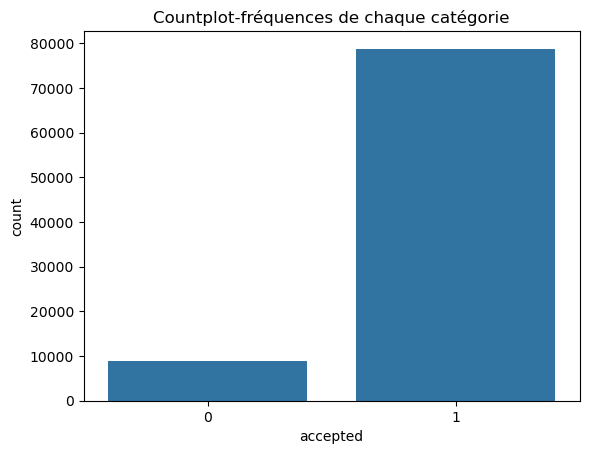

nombre de prêts accordés : 78762
nombre de prêts refusés : 8942


In [27]:
sns.countplot(x="accepted", data=data_clean)
plt.title("Countplot-fréquences de chaque catégorie")
plt.show()  

print("nombre de prêts accordés :", (data_clean["accepted"] == 1).sum())   
print("nombre de prêts refusés :", (data_clean["accepted"] == 0).sum())   

On constate un fort déséquilibre dans le dataset. En effet, il y a beaucoup plus de prêts accordés (78762) que de prêts refusés (8942). 
Plus précisément, il y a près de 9 fois plus de prêts accordés que de prêts refusés.

#### Matrice de corrélation linéaire entre toutes les variables :

Cette matrice permet de repérer les variables très corrélées entre elles (redondance) et celles corrélées à `accepted` (utiles).

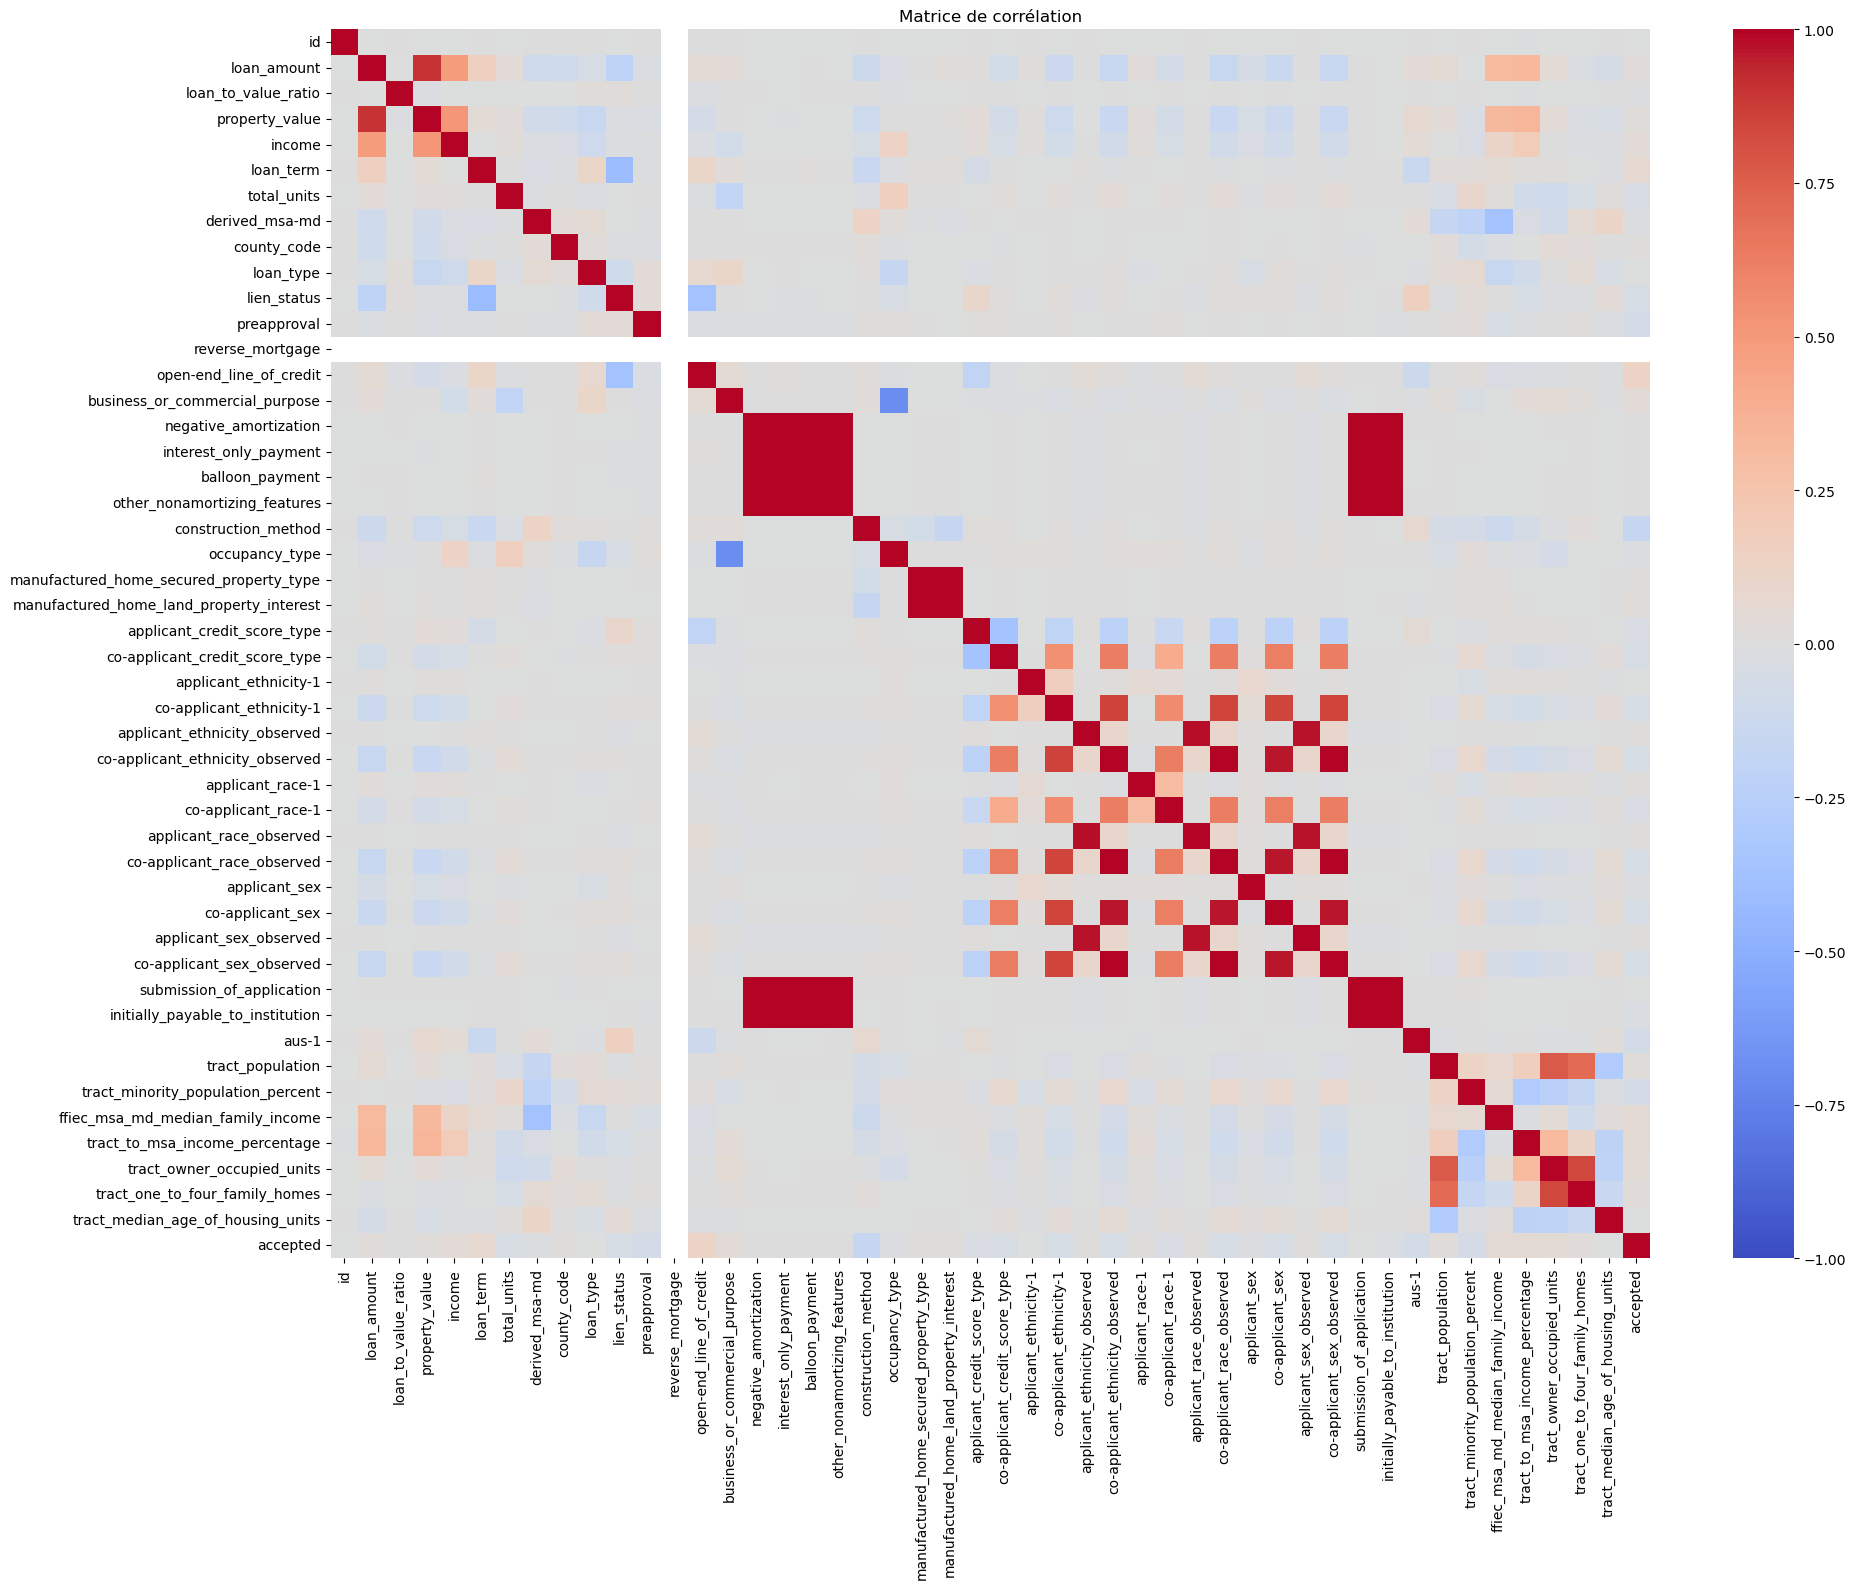

In [15]:
plt.figure(figsize=(20, 16))
sns.heatmap(data_clean.corr(numeric_only=True), annot=False, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.savefig("matrice_correlation_data_clean_train.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
print(data_clean["reverse_mortgage"].nunique())

1


##### Pour data_clean :

On constate que la variable `reverse_mortage` est constante. On peut donc l'enlever du dataset.

La variable cible `accepted` n'est fortement corrélée à aucune variable. Sa ligne est presque entièrement grise (proche de 0). Aucune variable ne prédit donc l'acceptation à elle seule de façon linéaire. Cela ne veut pas dire que le problème est impossible : l'effet peut venir d'interactions ou de relations non linéaires.

`loan_amount` et `property_value` : corrélation très forte (0,9), logique : on emprunte en proportion de la valeur du bien. 
`income` est modérément corrélé aux deux (0,5).
`ffiec_msa_md_median_family_income` et `tract_to_msa_income_percentage` sont modérément liés à loan_amount et property_value (0,3)
De ces observations, on choisit de ne garder qu'une seule des deux variables entre `loan_amount` et `property_value` qui semblent être redondantes. On choisit de garder `loan_amount`.

##### Pour data_train : 

On constate beaucoup plus de corrélations.

On peut conclure que l'on perd en corrélation et donc en information avec data_clean on va donc essayer une autre méthode que de juste retirer les lignes NaN

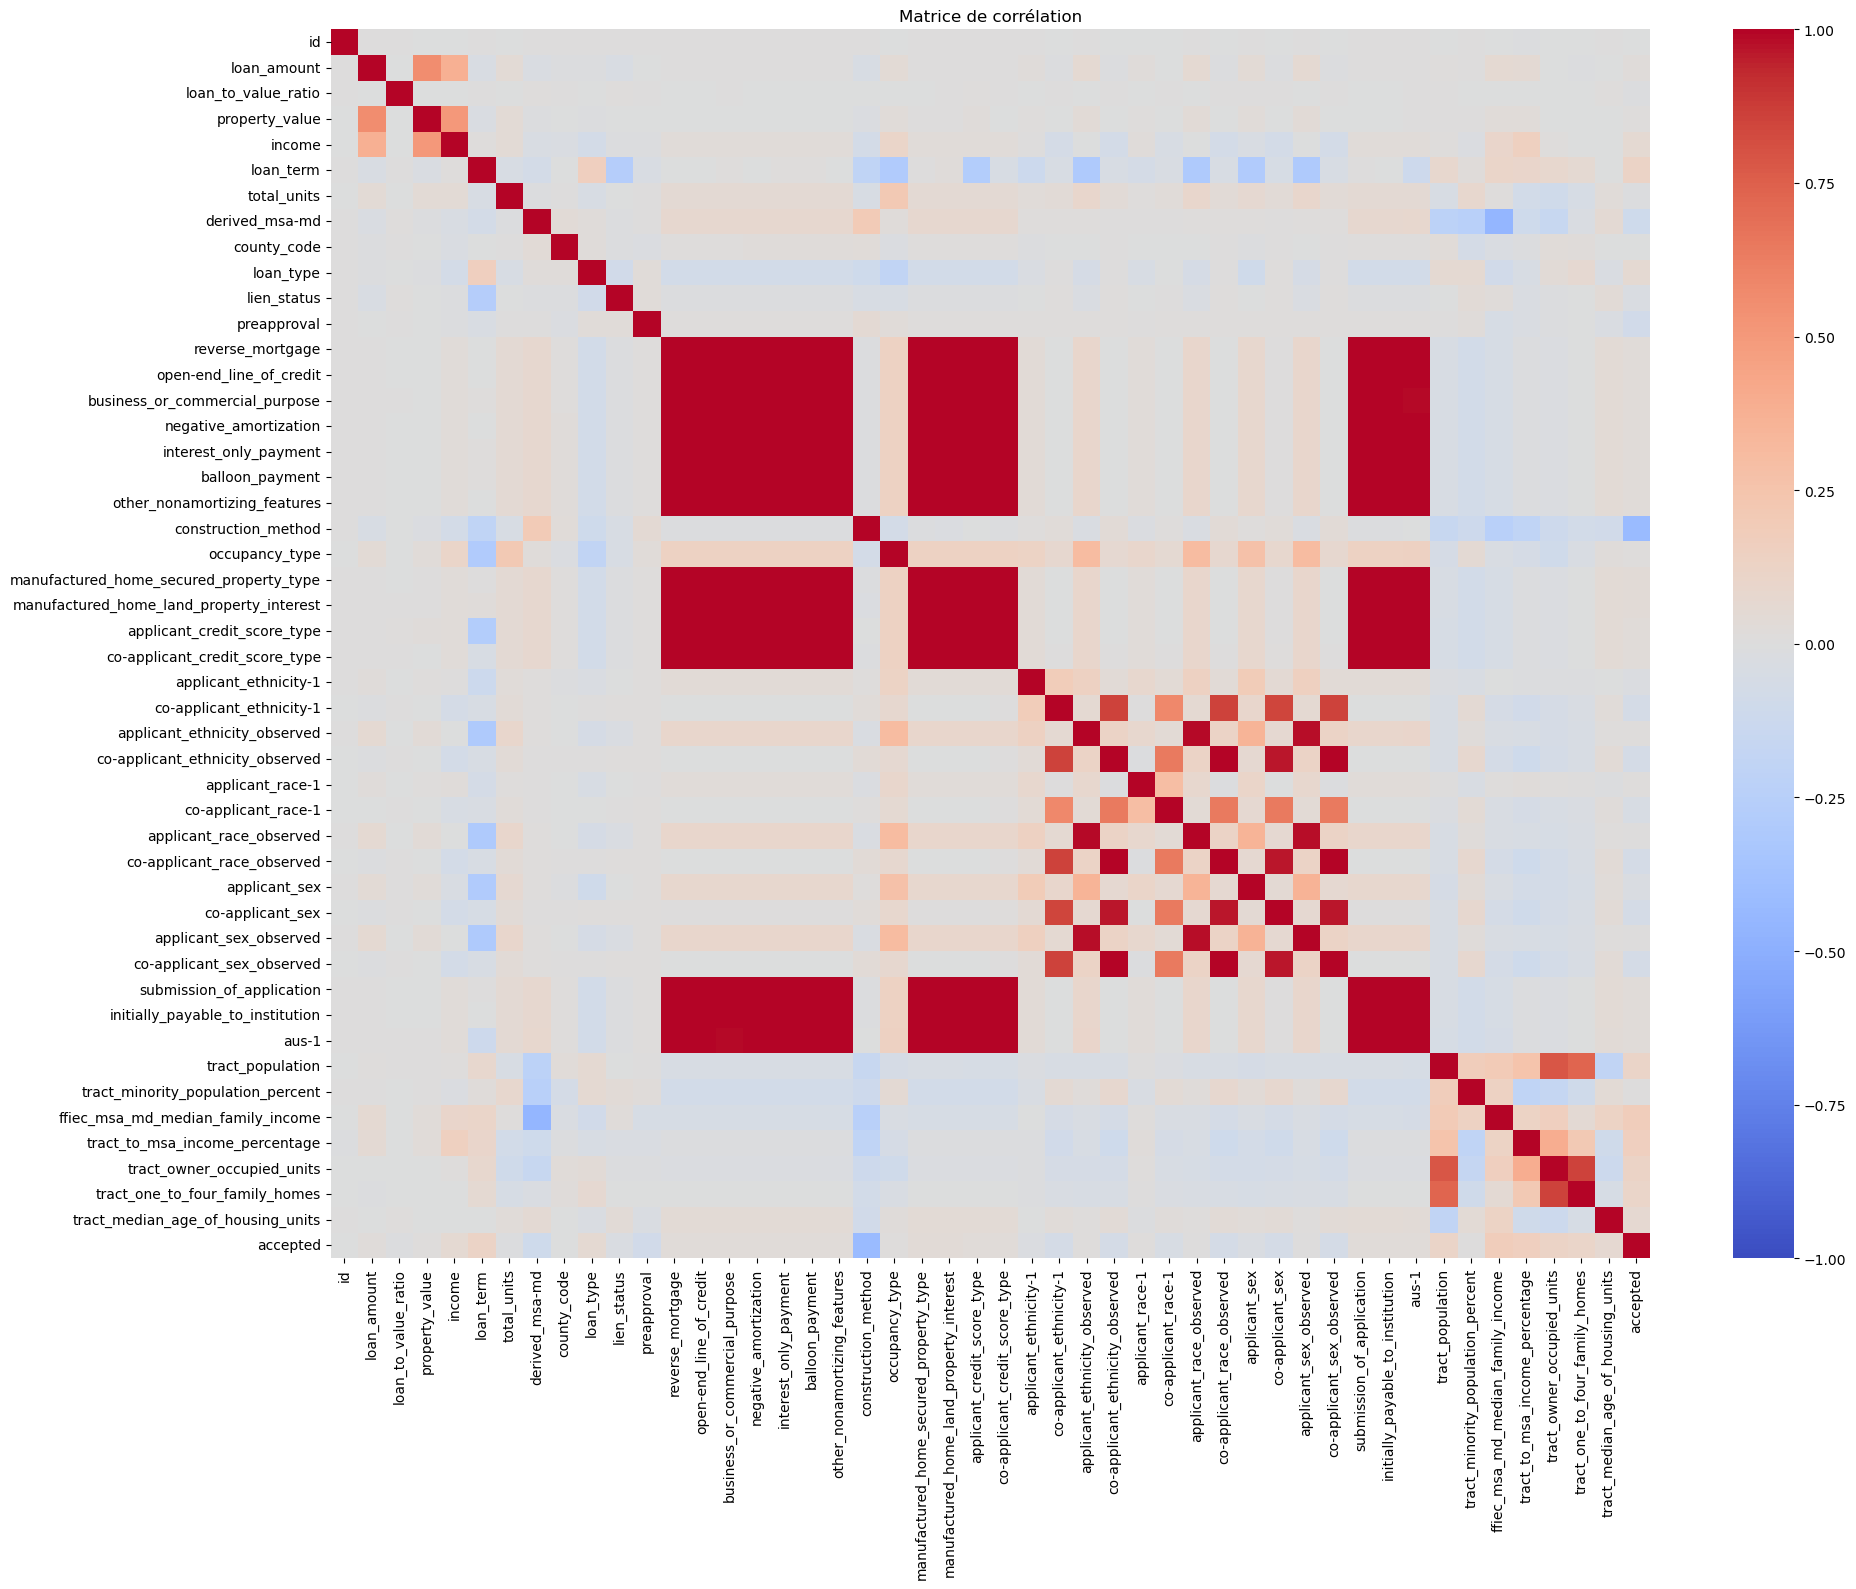

In [16]:
plt.figure(figsize=(20, 16))
sns.heatmap(data_train.corr(numeric_only=True), annot=False, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.savefig("matrice_correlation_data_train.png", dpi=300, bbox_inches="tight")
plt.show()

#### Coefficient de Pearson - Corrélation linéaire entre les variables et la variable cible `accepted` :

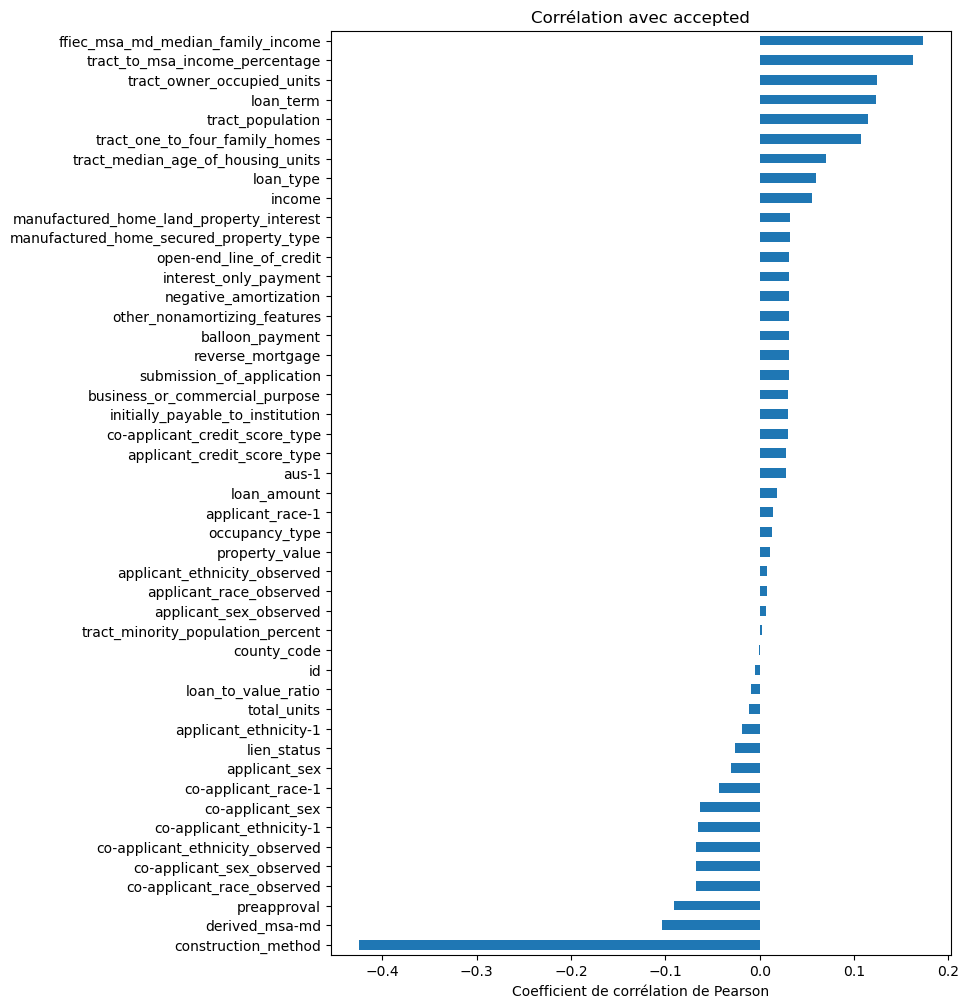

In [35]:
corr = data_clean.corr(numeric_only=True)
corr_cible = corr["accepted"].drop("accepted").sort_values()
plt.figure(figsize=(8, 12))
corr_cible.plot(kind="barh")
plt.title("Corrélation avec accepted")
plt.xlabel("Coefficient de corrélation de Pearson")
plt.savefig("matrice_correlation_accepted.png", dpi=300, bbox_inches="tight")
plt.show()

Comment lire ce plot : 
Plus le coefficient est proche de 1 : quand la variable augmente, la probabilité que le prêt soit accordé (1) a tendance à augmenter.
Plus le coefficient est proche de -1 : quand la variable augmente, la probabilité d'acceptation a tendance à diminuer.
Si le coefficient est proche de 0 : pas de lien linéaire marqué avec la cible.

Attention, pour les deux derniers plots, seul le lien linéaire est mesuré : une variable peut avoir une barre quasi nulle et pourtant être très utile (relation non linéaire, interaction avec d'autres variables). On ne supprime donc pas une variable uniquement parce que sa barre est courte.

In [10]:
# on s'est interessé qu'aux relations linéaires mais il n'y a pas que ça 
#variables continues :

df_avant = data_train
df_apres = data_clean

# df_avant / df_apres : datasets avant et après nettoyage
cols_num = ["income", "property_value", "loan_term", "loan_to_value_ratio", "total_units"] # g enlevé "debt_to_income_ratio"
res = []
for c in cols_num:
    a = df_avant[c].dropna()
    b = df_apres[c].dropna()
    ks = ks_2samp(a, b)
    res.append({
        "variable": c,
        "moy_avant": a.mean(), "moy_apres": b.mean(),
        "med_avant": a.median(), "med_apres": b.median(),
        "ks_stat": ks.statistic, "p_value": ks.pvalue,
    })

res = pd.DataFrame(res).sort_values("ks_stat", ascending=False)
print(res)

              variable      moy_avant      moy_apres  med_avant  med_apres  \
2            loan_term     337.748695     347.754766      360.0      360.0   
1       property_value  515903.694984  482555.185624   355000.0   375000.0   
0               income     154.181912     160.571661      107.0      113.0   
3  loan_to_value_ratio    6528.788724      85.298347       90.0       90.0   
4          total_units       1.038599       1.030683        1.0        1.0   

    ks_stat        p_value  
2  0.073837  1.034064e-223  
1  0.046623   8.406790e-89  
0  0.036219   8.539223e-54  
3  0.015235   1.551190e-09  
4  0.005113   1.644810e-01  


In [11]:
# variables catégorielles

# 1) Colonnes numériques qui sont en fait des codes
code_cols = ["county_code", "applicant_ethnicity-1", "co-applicant_ethnicity-1",
             "applicant_race-1", "co-applicant_race-1"]

# 2) Toutes les colonnes de texte, détectées automatiquement
text_cols = data_train.select_dtypes(exclude="number").columns.tolist()

# 3) Liste finale de toutes les catégorielles, sans doublons
cols_cat = list(dict.fromkeys(text_cols + code_cols))

for c in cols_cat:
    comp = pd.concat(
        [df_avant[c].value_counts(normalize=True),
         df_apres[c].value_counts(normalize=True)],
        axis=1, keys=["avant", "apres"]
    ).fillna(0)
    comp["ecart"] = comp["apres"] - comp["avant"]
    print(c); print(comp.sort_values("ecart", key=abs, ascending=False).head(10))

state_code
               avant     apres     ecart
state_code                              
CA          0.072617  0.076199  0.003582
TX          0.108605  0.105788 -0.002817
LA          0.013208  0.010421 -0.002787
AZ          0.025841  0.028277  0.002436
AL          0.019333  0.016932 -0.002401
WA          0.021819  0.024115  0.002296
MS          0.009801  0.007605 -0.002196
OK          0.013736  0.011562 -0.002175
FL          0.088312  0.090486  0.002174
KY          0.015003  0.013238 -0.001766
conforming_loan_limit
                          avant     apres     ecart
conforming_loan_limit                              
NC                     0.035682  0.037433  0.001751
C                      0.964117  0.962567 -0.001550
U                      0.000201  0.000000 -0.000201
derived_loan_product_type
                                  avant     apres     ecart
derived_loan_product_type                                  
Conventional:First Lien        0.697333  0.668567 -0.028766
FHA:First

KeyError: 'co-applicant_age'

Le problème avec ce nettoyage : 
1) On perd trop d'information en enlevant la variable `co-applicant_age` : cette colonne contient l'âge du co-demandeur (la deuxième personne qui signe le prêt, par exemple le conjoint). Dans le dataset, elle a 58 693 NaN sur 105 000 lignes. Mais ces NaN ne veulent pas dire « on ne sait pas », ils veulent presque sûrement dire « il n'y a pas de co-demandeur » : la personne a demandé le prêt seule.
2) On perd trop d'information en supprimant les lignes NaN : on peut plutôt remplir les trous en imputant la médiane pour les variables continues et en créant une catégorie "inconnue" pour les variables catégorielles. 


On crée une nouvelle colonne qui répond simplement à la question « y a-t-il un co-demandeur ? » :
1 : oui
2 : non

In [53]:
data_train = pd.read_csv("train.csv")
data_train["has_coapplicant"] = data_train["co-applicant_age"].notnull().astype(int)

Pour les **variables continues** : 

Au lieu de supprimer toute la ligne dès qu'une seule case est vide, on remplit la case vide avec une valeur raisonnable : la **médiane**. On préfère la médiane à la moyenne parce qu'elle n'est pas faussée par les valeurs extrêmes.

Remplir avec la médiane a un défaut : le modèle ne peut plus distinguer une vraie valeur d'une valeur qu'on a ajouter. Or le fait qu'une valeur soit manquante peut être une information en soi. Par exemple, si le revenu n'est pas renseigné, c'est peut-être parce que le dossier a été refusé très tôt, avant d'être complété. On ajoute donc une colonne qui garde la trace de ce qui était manquant, c'est un **indicateur de manquant**.

In [54]:
# 1) Tranches en texte -> valeurs numériques (milieu de chaque tranche)
dti_tranches = {
    "<20%": 15, "20%-<30%": 25, "30%-<36%": 33,
    "50%-60%": 55, ">60%": 65,
}

data_train["debt_to_income_ratio"] = data_train["debt_to_income_ratio"].replace(dti_tranches)

# 2) Pour chaque colonne numérique : conversion, indicateur de manquant, médiane
num_cols = ["income", "property_value", "loan_term", "loan_to_value_ratio",
            "debt_to_income_ratio", "total_units"]

for col in num_cols:
    data_train[col + "_missing"] = data_train[col].isnull().astype(int)  # 1) on note les manquants
    data_train[col] = data_train[col].fillna(data_train[col].median())   # 2) on remplit


Pour les **variables catégorielles** : 

On ne peut pas calculer une médiane sur des catégories. Il faut une autre approche. Plutôt que de supprimer la ligne ou d'inventer une valeur, on remplace le NaN par une catégorie à part entière : "Inconnu".

In [55]:
cat_cols = ["state_code", "county_code", "applicant_ethnicity-1",
            "co-applicant_ethnicity-1", "applicant_race-1",
            "co-applicant_race-1", "applicant_age"]

print(data_train[cat_cols].dtypes)

# 1) Colonnes déjà en texte : simple
for col in ["state_code", "applicant_age"]:
    data_train[col] = data_train[col].fillna("Inconnu")

# 2) Colonnes numériques qui sont en fait des codes : conversion en texte propre
code_cols = ["county_code", "applicant_ethnicity-1", "co-applicant_ethnicity-1",
             "applicant_race-1", "co-applicant_race-1"]

for col in code_cols:
    data_train[col] = (
        data_train[col]
        .astype("Int64")     # 6037.0 -> 6037 (accepte les NaN)
        .astype("string")    # on passe en texte
        .fillna("Inconnu")   # NaN -> "Inconnu"
    )

state_code                   object
county_code                 float64
applicant_ethnicity-1       float64
co-applicant_ethnicity-1    float64
applicant_race-1            float64
co-applicant_race-1         float64
applicant_age                object
dtype: object


Vérification que l'on a bien remplit toutes les valeurs manquantes :

In [56]:
data_train.isnull().sum()

id                              0
loan_amount                     0
loan_to_value_ratio             0
property_value                  0
income                          0
                               ..
property_value_missing          0
loan_term_missing               0
loan_to_value_ratio_missing     0
debt_to_income_ratio_missing    0
total_units_missing             0
Length: 65, dtype: int64

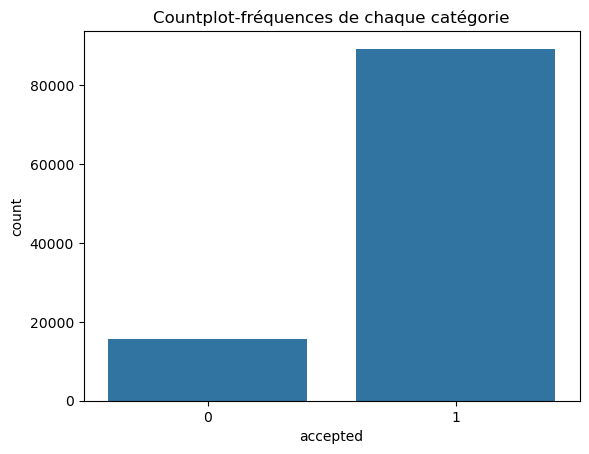

nombre de prêts accordés : 89244
nombre de prêts refusés : 15756


In [58]:
sns.countplot(x="accepted", data=data_train)
plt.title("Countplot-fréquences de chaque catégorie")
plt.show()  

print("nombre de prêts accordés :", (data_train["accepted"] == 1).sum())   
print("nombre de prêts refusés :", (data_train["accepted"] == 0).sum())   

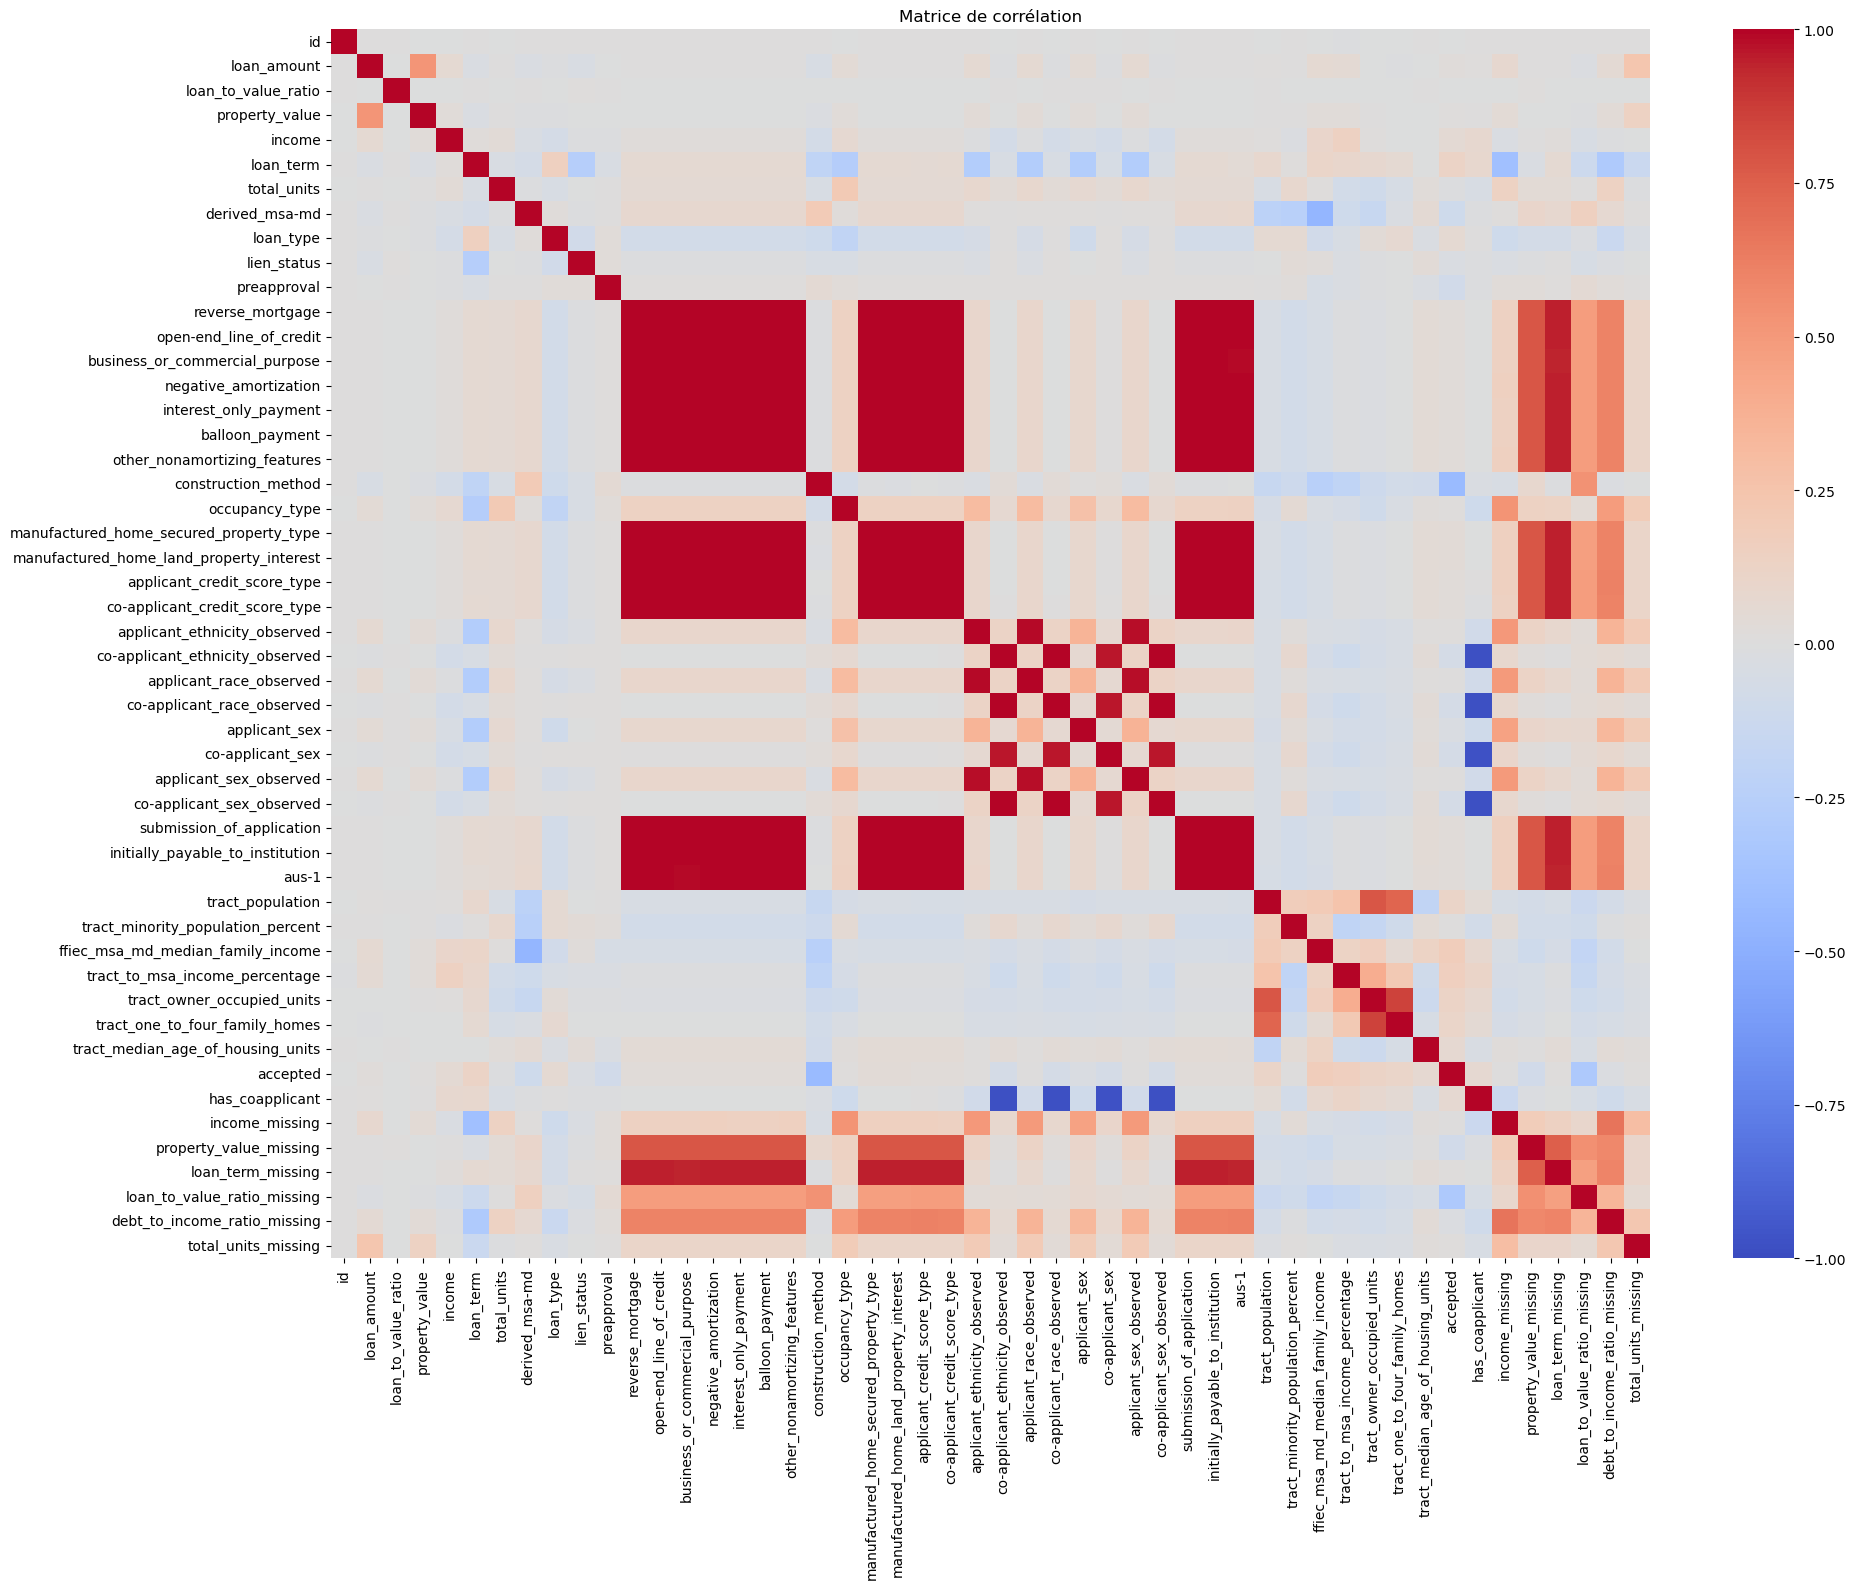

In [59]:
plt.figure(figsize=(20, 16))
sns.heatmap(data_train.corr(numeric_only=True), annot=False, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

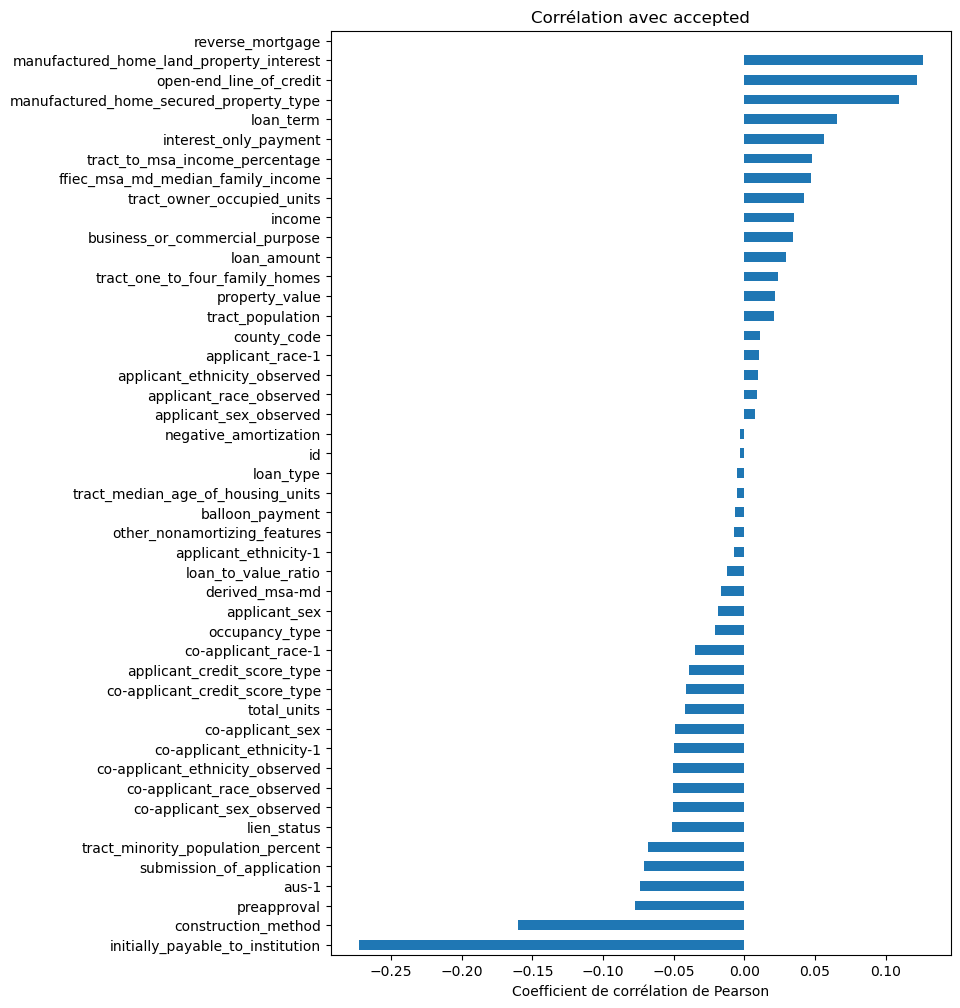

In [60]:
corr = data_clean.corr(numeric_only=True)
corr_cible = corr["accepted"].drop("accepted").sort_values()
plt.figure(figsize=(8, 12))
corr_cible.plot(kind="barh")
plt.title("Corrélation avec accepted")
plt.xlabel("Coefficient de corrélation de Pearson")
plt.show()

In [7]:
# Normaliser les données ?